# ML Assignment 2 - Classification models

Dataset: Mobile Price Classification, from Kaggle
(https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification).

The labeled file is `train.csv` on Kaggle: 2000 phones, 20 features, and `price_range`
(0 = low, 1 = medium, 2 = high, 3 = very high). Kaggle's own `test.csv` has no labels,
so it cannot be used to compute the metrics. I downloaded the labeled file and saved it as
`data/mobile_price_full.csv`.

This notebook:
1. loads that file, looks at it and checks whether it needs cleaning
2. makes a train/test split
3. for each of the 5 models (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM)
   fits a baseline, then tunes it with cross-validation on the training set only
4. reports Accuracy, AUC, Precision, Recall, F1 and MCC on the test set
5. saves the five tuned models to `model/` and the test set to `test_data.csv`

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay)

# lbfgs prints convergence warnings for some C values in the grid
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', module='sklearn')

SEED = 7
TARGET = 'price_range'
os.makedirs('model', exist_ok=True)
os.makedirs('data', exist_ok=True)

## 1. Load the data

In [2]:
df = pd.read_csv('data/mobile_price_full.csv')
print(df.shape)
df.head()

(2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
print(df[TARGET].value_counts().sort_index())
print('feature count:', df.shape[1] - 1)

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64
feature count: 20


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


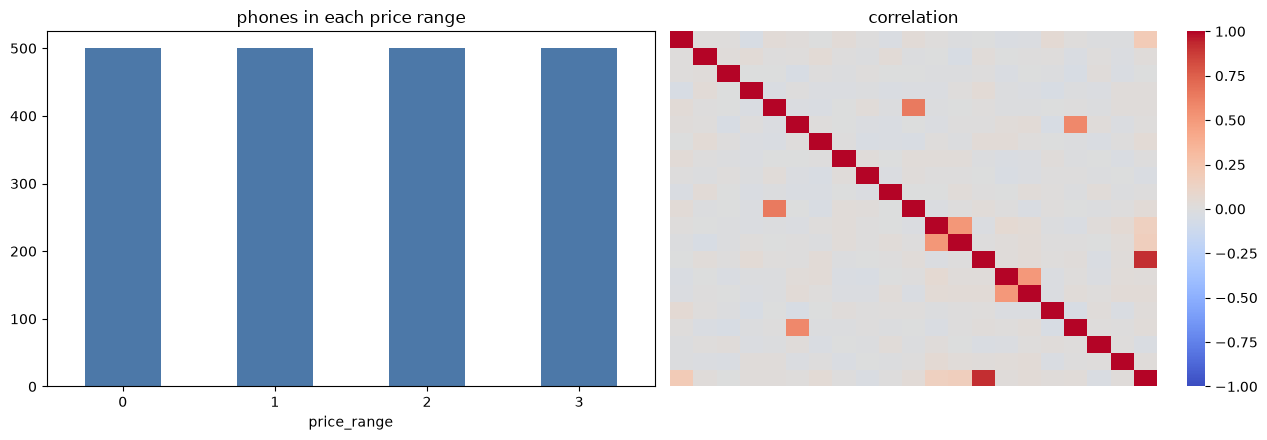

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color='#4c78a8')
ax[0].set_title('phones in each price range')
ax[0].set_xlabel('price_range')
ax[0].tick_params(axis='x', rotation=0)

corr = df.corr()
sns.heatmap(corr, ax=ax[1], cmap='coolwarm', xticklabels=False, yticklabels=False, vmin=-1, vmax=1)
ax[1].set_title('correlation')
plt.tight_layout()
plt.show()

### 1.1 Does the data need cleaning?

In [6]:
print('missing values :', df.isnull().sum().sum())
print('duplicate rows :', df.duplicated().sum())
# a screen can't be 0 cm wide or 0 pixels high, these look like missing values stored as 0
print('px_height == 0 :', (df['px_height'] == 0).sum())
print('sc_w == 0      :', (df['sc_w'] == 0).sum())

missing values : 0
duplicate rows : 0
px_height == 0 : 2
sc_w == 0      : 180


No missing values, no duplicates, classes exactly balanced (500 each).

The only odd thing is `sc_w = 0` on 180 rows and `px_height = 0` on 2 rows. I tried replacing those zeros
with the training median (a `SimpleImputer(missing_values=0)` step) and compared 5-fold CV accuracy on
the training set, using the final tuned settings of each model. The change was between -0.12 and +0.06
percentage points (about 2 phones out of 1600 at most), which is noise, so I left the values as they are. Screen width barely relates to price anyway (see the F-scores below).

## 2. Train / test split

In [7]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

train_df = X_train.copy()
train_df[TARGET] = y_train.values
test_df = X_test.copy()
test_df[TARGET] = y_test.values

train_df.to_csv('data/train_data.csv', index=False)
# test set goes to the project root, the submission asks for test_data.csv there
test_df.to_csv('test_data.csv', index=False)

print('train', train_df.shape, 'test', test_df.shape)
print(y_train.value_counts().sort_index().to_dict())

train (1600, 21) test (400, 21)
{0: 400, 1: 400, 2: 400, 3: 400}


### 2.1 Which features matter?

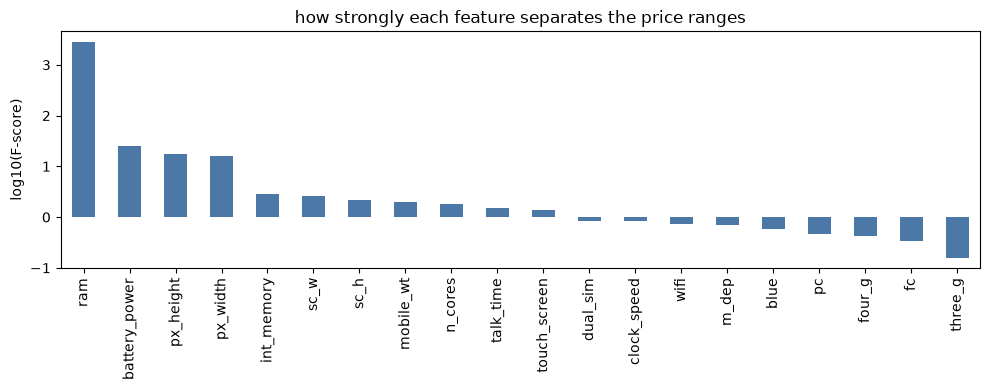

ram              2803.1
battery_power      25.6
px_height          17.2
px_width           16.2
int_memory          2.8
sc_w                2.6
sc_h                2.2
mobile_wt           2.0
n_cores             1.8
talk_time           1.5
touch_screen        1.4
dual_sim            0.8
clock_speed         0.8
wifi                0.7
m_dep               0.7
blue                0.6
pc                  0.5
four_g              0.4
fc                  0.3
three_g             0.2
dtype: float64

In [8]:
# ANOVA F-score of each feature against price_range, training rows only
f_scores, _ = f_classif(X_train, y_train)
f_scores = pd.Series(f_scores, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
np.log10(f_scores).plot.bar(ax=ax, color='#4c78a8')
ax.set_ylabel('log10(F-score)')
ax.set_title('how strongly each feature separates the price ranges')
plt.tight_layout()
plt.show()
f_scores.round(1)

`ram` is by far the strongest feature. After it come `battery_power`, `px_height` and `px_width`, and
everything else is close to zero. This matters most for KNN: in a distance calculation every scaled feature
counts equally, so 16 weak features drown out RAM.

So for tuning, feature selection is part of the pipeline. `SelectKBest(f_classif, k)` keeps the k best
features, and k is tuned along with the model settings. Because it sits inside the pipeline, it is fit on the
training folds only, and the saved model still accepts all 20 columns from the test CSV.

### 2.2 Evaluation helpers

There are 4 classes, so Precision, Recall and F1 are weighted averages, and AUC is one-vs-rest, also weighted.
All tuning uses 5-fold stratified CV on the training set. The test set is only used for the final scores.

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
K_OPTIONS = [4, 6, 10, 20]   # 20 = keep every feature


def get_scores(name, model, X_te, y_te):
    pred = model.predict(X_te)
    prob = model.predict_proba(X_te)
    return {
        'ML Model Name': name,
        'Accuracy': accuracy_score(y_te, pred),
        'AUC': roc_auc_score(y_te, prob, multi_class='ovr', average='weighted'),
        'Precision': precision_score(y_te, pred, average='weighted'),
        'Recall': recall_score(y_te, pred, average='weighted'),
        'F1': f1_score(y_te, pred, average='weighted'),
        'MCC': matthews_corrcoef(y_te, pred),
    }


def tune(pipe, grid):
    search = GridSearchCV(pipe, grid, cv=cv, scoring='accuracy', n_jobs=-1)
    search.fit(X_train, y_train)
    print('best CV accuracy:', round(search.best_score_, 4))
    print('best params     :', search.best_params_)
    return search.best_estimator_


def kept_features(model):
    return list(X.columns[model.named_steps['pick'].get_support()])


baseline, results, trained = [], [], {}
labels = ['0', '1', '2', '3']

## 3. Models

### 3.1 Logistic Regression

In [10]:
lr_base = Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=5000))])
lr_base.fit(X_train, y_train)
baseline.append(get_scores('Logistic Regression', lr_base, X_test, y_test))

lr = tune(
    Pipeline([('pick', SelectKBest(f_classif)), ('scale', StandardScaler()),
              ('clf', LogisticRegression(max_iter=5000))]),
    {'pick__k': K_OPTIONS, 'clf__C': [1, 10, 100, 1000, 10000]},
)
trained['Logistic Regression'] = lr
results.append(get_scores('Logistic Regression', lr, X_test, y_test))
pd.DataFrame([baseline[-1], results[-1]], index=['baseline', 'tuned']).round(4)

best CV accuracy: 0.9694
best params     : {'clf__C': 1000, 'pick__k': 20}


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
baseline,Logistic Regression,0.9725,0.9990,0.9728,0.9725,0.9725,0.9634
tuned,Logistic Regression,0.9825,0.9994,0.9826,0.9825,0.9825,0.9767


Less regularisation (bigger C) helps. The classes are almost linearly separable on RAM plus a few other
features, and the default C = 1 pulls the weights back too much.

### 3.2 Decision Tree

In [11]:
dt_base = DecisionTreeClassifier(random_state=SEED)
dt_base.fit(X_train, y_train)
baseline.append(get_scores('Decision Tree', dt_base, X_test, y_test))

dtree = tune(
    Pipeline([('pick', SelectKBest(f_classif)), ('clf', DecisionTreeClassifier(random_state=SEED))]),
    {'pick__k': K_OPTIONS,
     'clf__criterion': ['gini', 'entropy'],
     'clf__max_depth': [6, 8, 10, 12, None],
     'clf__min_samples_leaf': [1, 2, 4, 8]},
)
print('features kept:', kept_features(dtree))
trained['Decision Tree'] = dtree
results.append(get_scores('Decision Tree', dtree, X_test, y_test))
pd.DataFrame([baseline[-1], results[-1]], index=['baseline', 'tuned']).round(4)

best CV accuracy: 0.8556
best params     : {'clf__criterion': 'entropy', 'clf__max_depth': 12, 'clf__min_samples_leaf': 1, 'pick__k': 4}
features kept: ['battery_power', 'px_height', 'px_width', 'ram']


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
baseline,Decision Tree,0.8275,0.8850,0.8263,0.8275,0.8259,0.7706
tuned,Decision Tree,0.8675,0.9117,0.8673,0.8675,0.8660,0.8242


### 3.3 K-Nearest Neighbors

In [12]:
knn_base = Pipeline([('scale', StandardScaler()), ('clf', KNeighborsClassifier())])
knn_base.fit(X_train, y_train)
baseline.append(get_scores('KNN', knn_base, X_test, y_test))

knn = tune(
    Pipeline([('pick', SelectKBest(f_classif)), ('scale', StandardScaler()), ('clf', KNeighborsClassifier())]),
    {'pick__k': K_OPTIONS,
     'clf__n_neighbors': [11, 21, 31, 41, 51, 71],
     'clf__weights': ['uniform', 'distance'],
     'clf__p': [1, 2]},
)
print('features kept:', kept_features(knn))
trained['KNN'] = knn
results.append(get_scores('KNN', knn, X_test, y_test))
pd.DataFrame([baseline[-1], results[-1]], index=['baseline', 'tuned']).round(4)

best CV accuracy: 0.91
best params     : {'clf__n_neighbors': 51, 'clf__p': 1, 'clf__weights': 'distance', 'pick__k': 4}
features kept: ['battery_power', 'px_height', 'px_width', 'ram']


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
baseline,KNN,0.515,0.7548,0.5281,0.515,0.5152,0.3558
tuned,KNN,0.915,0.9920,0.9163,0.915,0.9150,0.8871


This is the biggest jump. Keeping only the 4 strong features means the distance is mostly about RAM,
battery and screen resolution. Weighting neighbours by distance with Manhattan distance (p = 1) also helped.

### 3.4 Naive Bayes (Gaussian)

In [13]:
# features are numeric, so GaussianNB rather than MultinomialNB
nb_base = GaussianNB()
nb_base.fit(X_train, y_train)
baseline.append(get_scores('Naive Bayes', nb_base, X_test, y_test))

nb_model = tune(
    Pipeline([('pick', SelectKBest(f_classif)), ('clf', GaussianNB())]),
    {'pick__k': K_OPTIONS},
)
trained['Naive Bayes'] = nb_model
results.append(get_scores('Naive Bayes', nb_model, X_test, y_test))
pd.DataFrame([baseline[-1], results[-1]], index=['baseline', 'tuned']).round(4)

best CV accuracy: 0.8075
best params     : {'pick__k': 20}


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
baseline,Naive Bayes,0.8075,0.9573,0.806,0.8075,0.8059,0.7439
tuned,Naive Bayes,0.8075,0.9573,0.806,0.8075,0.8059,0.7439


Naive Bayes has nothing real to tune, and dropping features did not help in CV, so it keeps all 20 and the
tuned model is the same as the baseline. Its limit is the independence assumption, not the settings.

### 3.5 Support Vector Machine

In [14]:
# probability=True gives predict_proba for the AUC score
svm_base = Pipeline([('scale', StandardScaler()),
                     ('clf', SVC(probability=True, random_state=SEED))])
svm_base.fit(X_train, y_train)
baseline.append(get_scores('Support Vector Machine', svm_base, X_test, y_test))

svm = tune(
    Pipeline([('pick', SelectKBest(f_classif)), ('scale', StandardScaler()), ('clf', SVC())]),
    [{'pick__k': K_OPTIONS, 'clf__kernel': ['linear'], 'clf__C': [1, 10, 100, 1000]},
     {'pick__k': K_OPTIONS, 'clf__kernel': ['rbf'], 'clf__C': [10, 100, 1000],
      'clf__gamma': [0.001, 0.01, 'scale']}],
)
# grid search ran without probability (much faster), switch it on for the final fit.
# predict() does not depend on it, so the chosen model behaves the same
svm.set_params(clf__probability=True, clf__random_state=SEED)
svm.fit(X_train, y_train)
print('features kept:', kept_features(svm))

trained['Support Vector Machine'] = svm
results.append(get_scores('Support Vector Machine', svm, X_test, y_test))
pd.DataFrame([baseline[-1], results[-1]], index=['baseline', 'tuned']).round(4)

best CV accuracy: 0.9675
best params     : {'clf__C': 100, 'clf__kernel': 'linear', 'pick__k': 10}
features kept: ['battery_power', 'int_memory', 'mobile_wt', 'n_cores', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time']


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
baseline,Support Vector Machine,0.9025,0.9876,0.9030,0.9025,0.9022,0.8704
tuned,Support Vector Machine,0.9775,0.9994,0.9776,0.9775,0.9775,0.9700


CV picked a linear kernel. The RBF kernel's extra flexibility isn't needed here, because the boundaries
between price ranges are close to straight cuts.

## 4. Comparison

In [15]:
base_table = pd.DataFrame(baseline).set_index('ML Model Name')
comparison = pd.DataFrame(results).set_index('ML Model Name')

print('Baseline (default settings, all features)')
display(base_table.round(4))
print('Tuned (final models)')
display(comparison.round(4))

Baseline (default settings, all features)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9725,0.9990,0.9728,0.9725,0.9725,0.9634
Decision Tree,0.8275,0.8850,0.8263,0.8275,0.8259,0.7706
KNN,0.5150,0.7548,0.5281,0.5150,0.5152,0.3558
Naive Bayes,0.8075,0.9573,0.8060,0.8075,0.8059,0.7439
Support Vector Machine,0.9025,0.9876,0.9030,0.9025,0.9022,0.8704


Tuned (final models)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9825,0.9994,0.9826,0.9825,0.9825,0.9767
Decision Tree,0.8675,0.9117,0.8673,0.8675,0.8660,0.8242
KNN,0.9150,0.9920,0.9163,0.9150,0.9150,0.8871
Naive Bayes,0.8075,0.9573,0.8060,0.8075,0.8059,0.7439
Support Vector Machine,0.9775,0.9994,0.9776,0.9775,0.9775,0.9700


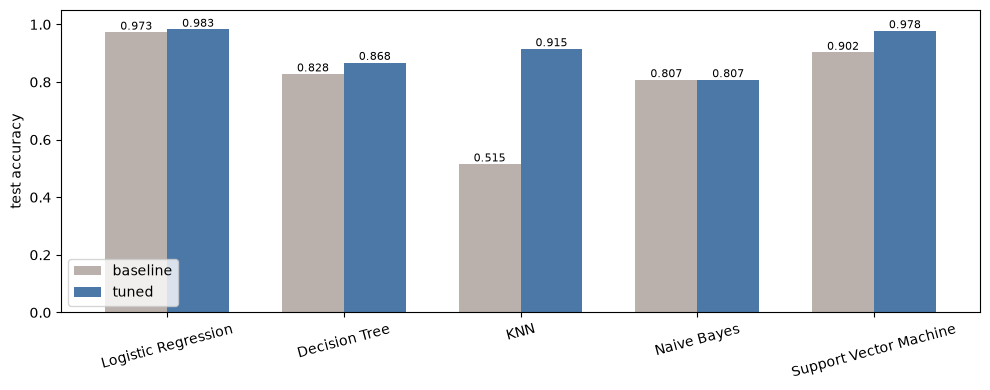

In [16]:
base_table.round(4).to_csv('model/metrics_baseline.csv')
comparison.round(4).to_csv('model/metrics_summary.csv')

acc = pd.DataFrame({'baseline': base_table['Accuracy'], 'tuned': comparison['Accuracy']})
fig, ax = plt.subplots(figsize=(10, 4))
acc.plot.bar(ax=ax, width=0.7, color=['#bab0ac', '#4c78a8'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('test accuracy')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=15)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.show()

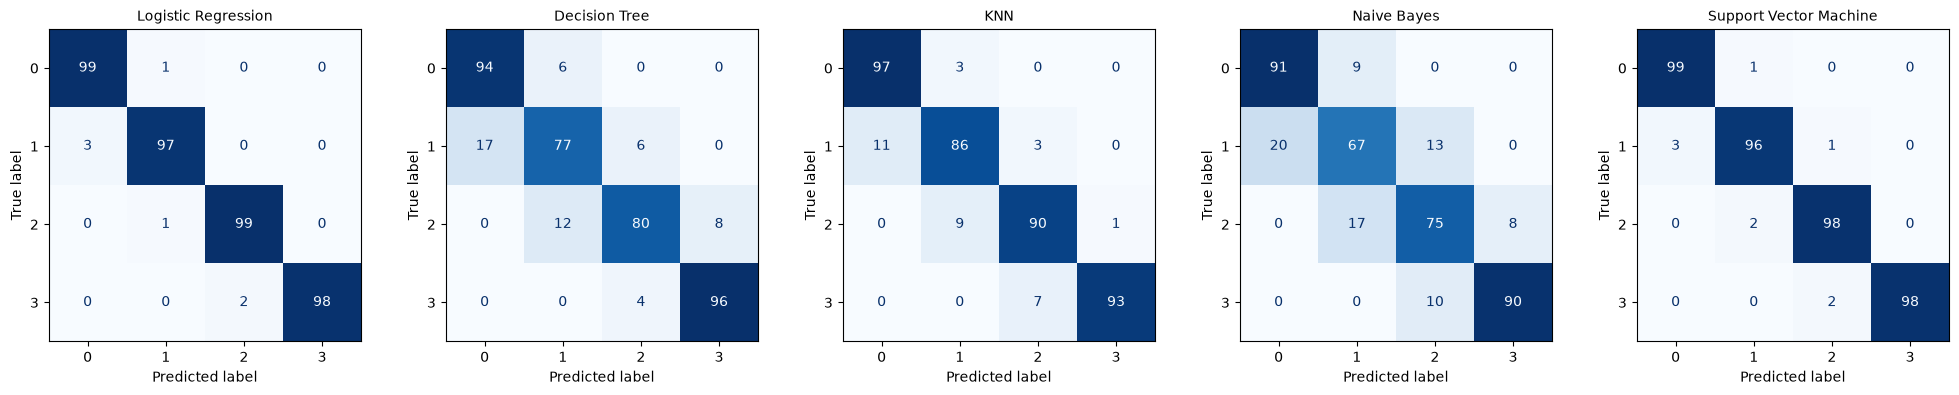

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8))
for ax, (name, m) in zip(axes, trained.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

## 5. Save the models

In [18]:
file_names = {
    'Logistic Regression': 'logistic_regression.joblib',
    'Decision Tree': 'decision_tree.joblib',
    'KNN': 'knn.joblib',
    'Naive Bayes': 'naive_bayes.joblib',
    'Support Vector Machine': 'svm.joblib',
}
for name, m in trained.items():
    joblib.dump(m, os.path.join('model', file_names[name]))

print(sorted(os.listdir('model')))

['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'metrics_baseline.csv', 'metrics_summary.csv', 'naive_bayes.joblib', 'svm.joblib']


In [19]:
# reload from disk and score the saved test file, should match the tuned table above
chk = pd.read_csv('test_data.csv')
for name, fn in file_names.items():
    m = joblib.load(os.path.join('model', fn))
    acc = accuracy_score(chk[TARGET], m.predict(chk.drop(columns=TARGET)))
    print(f'{name:25s} {acc:.4f}')

Logistic Regression       0.9825
Decision Tree             0.8675
KNN                       0.9150
Naive Bayes               0.8075
Support Vector Machine    0.9775
